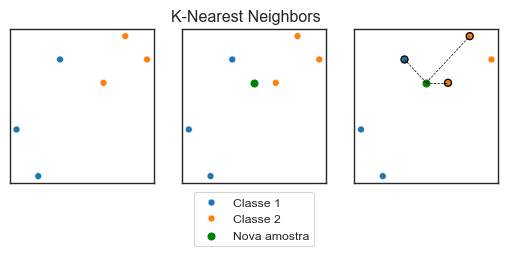

In [70]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.neighbors import KNeighborsClassifier
from matplotlib.patches import ConnectionPatch

matplotlib.use("pgf")
# matplotlib.use('macOsX')
matplotlib.rcParams.update({
    'axes.formatter.use_locale': True,
    "pgf.texsystem": "pdflatex",
    # 'font.family': 'serif',
    # 'text.usetex': True,
    # 'pgf.rcfonts': False,
})
%matplotlib inline

sns.set_style('white')
sns.set_context("paper", font_scale = 1)

# Set a random seed for reproducibility
np.random.seed(42)

# Generate simple data for two classes
class_1 = np.array([[4, 6], [2, 3], [3, 1]])
class_2 = np.array([[6, 5], [7, 7], [8, 6]])

# Combine the data and create labels
X = np.vstack((class_1, class_2))
y = np.array([0, 0, 0, 1, 1, 1])

fig, axes = plt.subplots(1, 3, figsize=(6.29707, 2))
plt.suptitle('K-Nearest Neighbors')

# Create a new point to classify
new_point = np.array([[5, 5]])

# Implement KNN with k=3
k = 3
knn = KNeighborsClassifier(n_neighbors=k)
knn.fit(X, y)

# Predict the class for the new point and get distances
distances, indices = knn.kneighbors(new_point)

# Plot the data with the new point
sns.scatterplot(ax=axes[0], x=X[:, 0], y=X[:, 1], hue=y, s=25)

sns.scatterplot(ax=axes[1], x=X[:, 0], y=X[:, 1], hue=y, s=25)
axes[1].scatter(new_point[:, 0], new_point[:, 1], c='green', s=25, label='Nova amostra')

sns.scatterplot(ax=axes[2], x=X[:, 0], y=X[:, 1], hue=y, s=25)
axes[2].scatter(new_point[:, 0], new_point[:, 1], c='green', s=25, label='Nova amostra')

# Plot the distances
for i, (dist, idx) in enumerate(zip(distances[0], indices[0])):
    point = X[idx]
    axes[2].plot([new_point[0, 0], point[0]], [new_point[0, 1], point[1]], 'k--', linewidth=0.5)

# Highlight the k nearest neighbors
for idx in indices[0]:
    axes[2].scatter(
        X[idx, 0],
        X[idx, 1],
        color='none',
        edgecolor='black',
        linewidth=1, 
        s=25
    )

for i in range(3):
    if i == 1:
        L = axes[i].legend(bbox_to_anchor=(0.96, -0.02))
        L.get_texts()[0].set_text('Classe 1')
        L.get_texts()[1].set_text('Classe 2')
    else:
        axes[i].get_legend().remove()

    axes[i].get_xaxis().set_visible(False)
    axes[i].get_yaxis().set_visible(False)

plt.savefig(
    f'knn_example.png',
    bbox_inches="tight"
)
plt.show()